# ¿Qué son los Outliers?

Los outliers en un dataset serán los valores que se “*escapan al rango en donde se concentran la mayoría de muestras*”. En otras palabras, son las muestras que están distantes de otras observaciones.

# Detección de Outliers

**¿Y por qué nos interesa detectar esos Outliers?**

Por que pueden afectar considerablemente a los resultados que pueda obtener un modelo de **Machine Learning** Para bien o para mal! Por eso hay que detectarlos, y tenerlos en cuenta.

Por ejemplo en la Regresión Lineal puede tener un impacto negativo en sus predicciones.

# Outliers Buenos vs Outliers Malos

Los Outliers pueden significar varias cosas:

1.   **ERROR**: Si tenemos un grupo de “edades de personas” y tenemos una persona con 160 años, seguramente sea un error de carga de datos. En este caso, la detección de outliers nos ayuda a detectar errores.
2.   **LIMITES**: En otros casos, podemos tener valores que se escapan del “grupo medio”, pero queremos mantener el dato modificado, para que no perjudique al aprendizaje del modelo de ML.
3.   **Punto de Interés**: Puede que sean los casos “anómalos” los que queremos detectar y que sean nuestro objetivo (y no nuestro enemigo).

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Outliers en 1 dimensión

In [ ]:
edades = np.array([22,22,23,23,23,23,26,27,27,28,30,30,30,30,31,32,33,34,80])
edad_unique, counts = np.unique(edades, return_counts=True)

In [ ]:
# Lista de los valores únicos de la variable 'edades'.
edad_unique

In [ ]:
# Cantidad de veces que estos se encuentran en el conjunto de datos.
counts

In [ ]:
# Aumentamos el tamaño de los conteos.
sizes = counts*100
# Creamos un vector con el mismo tamaño de valores únicos.
colors = ['blue']*len(edad_unique)
# El último valor del vector lo cambiamos a rojo.
colors[-1] = 'red'
# Creamos la línea punteada en el centro.
plt.axhline(1, color='k', linestyle='--')
# Graficamos los datos de las edades.
plt.scatter(edad_unique, np.ones(len(edad_unique)), s=sizes, color=colors)
plt.yticks([])
plt.show()

En azul los valores donde se concentra la mayoría de las muestras. En rojo un outlier o “valor extremo”.

# Outliers en 2 Dimensiones

Ahora supongamos que tenemos 2 variables: edad e ingresos. Hagamos una gráfica en 2D. Además, usaremos una fórmula para trazar un círculo que delimitará los valores outliers: Los valores que superen el valor de la “media más 2 desvíos estándar” (el área del círculo) quedarán en rojo.

In [ ]:
from math import pi

# Creamos datos sobre salarios anuales.
salario_anual_miles = np.array([16,20,15,21,19,17,33,22,31,32,56,30,22,31,30,16,2,22,23])
# Calculamos la media y la desviación estándar de los salarios.
media = salario_anual_miles.mean()
std_x = salario_anual_miles.std()*2
# Calculamos la media y la desviación estándar de las edades.
media_y = edades.mean()
std_y = edades.std()*2

In [ ]:
# Veamos los valores del salarario.
salario_anual_miles

In [ ]:
# Creamos un vector con el mismo tamaño del vector de salarios.
colors = ['blue']*len(salario_anual_miles)
# Tanto para los salarios como para las edades, preguntamos si la media es mayor
  # a la desviación estándar. Si es así coloreamos el punto de color rojo.
for index, x in enumerate(salario_anual_miles):
    if abs(x-media) > std_x:
        colors[index] = 'red'

for index, x in enumerate(edades):
    if abs(x-media_y) > std_y:
        colors[index] = 'red'

In [ ]:
# Dibujamos los datos de edad y salarios con colores.
plt.scatter(edades, salario_anual_miles, s=100, color=colors)
# Dibujamos las líneas horizontales y verticales punteadas que representan la
  # media de cada eje.
plt.axhline(media, color='k', linestyle='--')
plt.axvline(media_y, color='k', linestyle='--')

v=media     # Posición en y del centro.
u=media_y   # Posición en x del centro.
b=std_x     # Radio en el eje y.
a=std_y     # Radio en el eje x.

# Dibujamos el círculo que representa la desviación estándar.
t = np.linspace(0, 2*pi, 100)
plt.plot(u + a*np.cos(t), v + b*np.sin(t))
plt.xlabel('Edad')
plt.ylabel('Salario Anual (miles)')
plt.show()

Dentro del circulo azul, los valores que están en la media y en rojo los outliers: 3 valores que superan en más de 2 veces el desvío estándar.

Veamos la línea de tendencia de la misma distribución con y sin outliers:

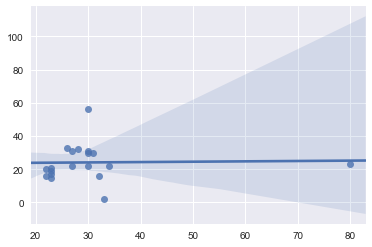

CON OUTLIERS: La línea de tendencia se mantiene plana sobre todo por el outlier de la edad.

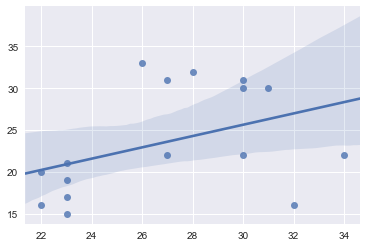

SIN OUTLIERS: Al quitar los outliers la tendencia empieza a tener pendiente.

Con esto nos podemos dar una idea de qué distinto podría resultar entrenar un modelo de Machine Learning con ó sin esas muestras anormales.

# Visualizar Outliers en 3D

Agregamos una tercera dimensión llamada “compras por mes” de cada usuario.

In [ ]:
from mpl_toolkits.mplot3d import Axes3D

In [ ]:
fig = plt.figure(figsize=(7,7))
ax = fig.add_subplot(projection='3d')

# Creamos un vector con el número de compras realizadas por cada individuo.
compras_mes = np.array([1,2,1,20,1,0,3,2,3,0,5,3,2,1,0,1,2,2,2])
# Calculamos la media y la desviación estándar de las compras.
media_z = compras_mes.mean()
std_z = compras_mes.std()*2

colors = ['blue']*len(compras_mes)

# Pintamos de color rojo aquel dato mayor a la desviación estándar.
for index, x in enumerate(compras_mes):
    if abs(x-media_z) > std_z:
        colors[index] = 'red'

# Dibujamos los datos.
ax.scatter(edades, salario_anual_miles, compras_mes, s=20, c=colors)
plt.xlabel('Edad')
plt.ylabel('Salario Anual (miles)')
ax.set_zlabel('Compras mensuales')

plt.show()

Vemos en 3 dimensiones que hay valores que se escapan a la "distribución normal". Valores atípicos en rojo.

En el caso de las compras mensuales, vemos que aparece un nuevo “punto rojo” en el eje Z. Debemos pensar si es un usuario que queremos descartar o que por el contrario, nos interesa analizar.

# Una gráfica de detección sencilla: Boxplots

Una gráfica bastante interesante por conocer es la de los Boxplots, muy utilizados en el mundo financiero. En nuestro caso, podemos visualizar las variables y en esa “cajita” veremos donde se concentra el 50 por ciento de nuestra distribución (percentiles 25% a 75%), los valores mínimos y máximos (las rayas en “T”) y -por supuesto- los outliers, esos “valores extraños” y alejados.

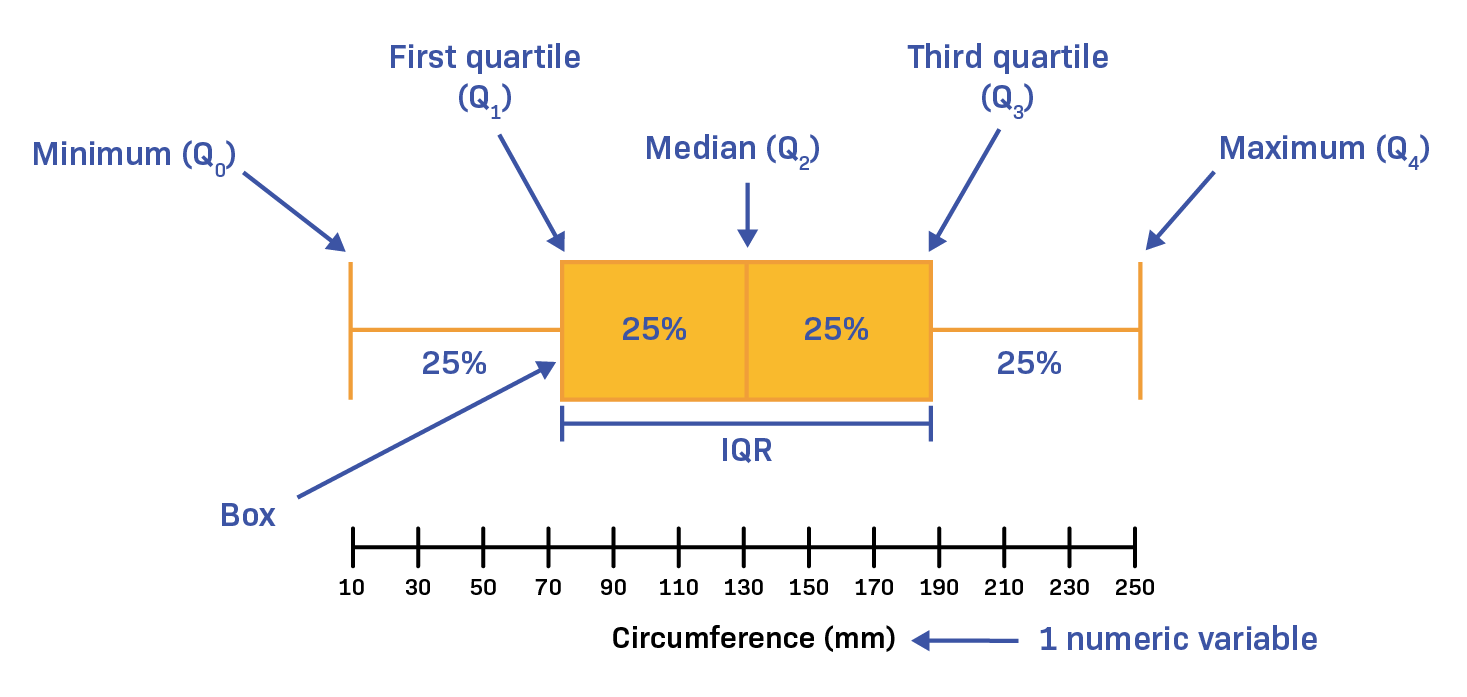

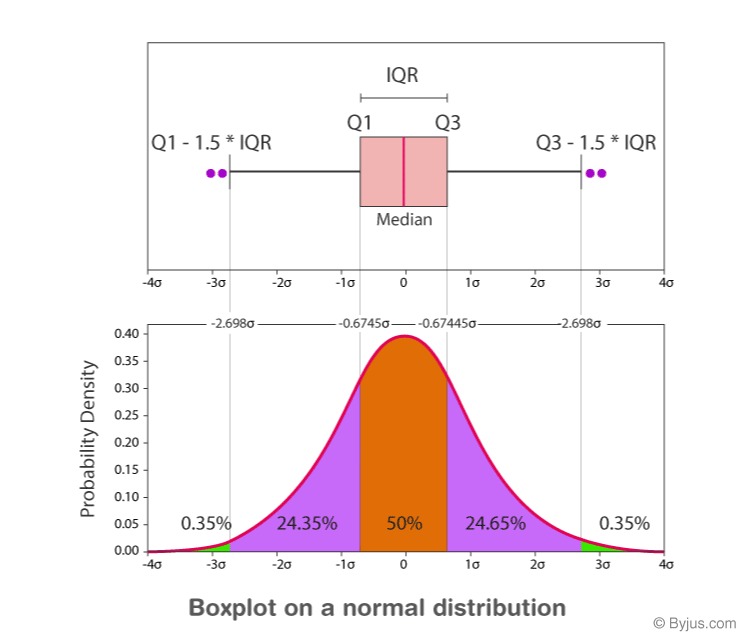

In [ ]:
green_diamond = dict(markerfacecolor='g', marker='D')
fig, ax = plt.subplots()
ax.set_title('Boxplot por Edades')
ax.boxplot(edades, flierprops=green_diamond, tick_labels=["Edad"]);

**Ejercicio:** Crear los `boxplots` correspondientes al salario y a las compras.

In [ ]:
# Boxplot de salario anual
fig, ax = plt.subplots()
ax.set_title('Boxplot por Salario Anual')
ax.boxplot(salario_anual_miles, flierprops=green_diamond, tick_labels=["Salario Anual (Miles)"]);

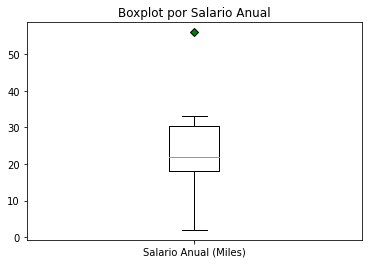

In [ ]:
# Boxplot de compras del mes
fig, ax = plt.subplots()
ax.set_title('Boxplot por Compras del Mes')
ax.boxplot(compras_mes, flierprops=green_diamond, tick_labels=["Compras del Mes"]);

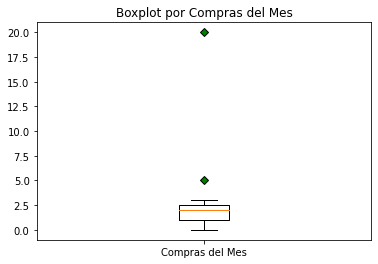

# Una vez detectados, ¿qué hago?

Dependiendo del tipo de análisis, podemos decidir si irnos por un camino o por otro. Por ejemplo, podríamos decidir:

*   Las edades fuera de la distribución normal, eliminar.
*   El salario que sobrepasa el límite, asignar el valor máximo (media + 2 sigmas).
*   Las compras mensuales, mantener sin cambios.

In [ ]:
!pip install pyod  # instala la librería

# PyOD: Librería Python para Detección de Outliers

En el código se utilizó una medida conocida para la detección de outliers que puede servir: la media de la distribución más 2 sigmas como frontera. Pero existen otras estrategias para delimitar outliers.

Una librería muy recomendada es `PyOD`. Posee diversas estrategias para detectar Outliers. Ofrece distintos algoritmos, entre ellos `KNN` (que analiza la cercanía entre muestras); así como otras técnicas como `PCA` o `Redes Neuronales`. Veamos cómo utilizarla en nuestro ejemplo.

In [ ]:
from pyod.models.knn import KNN
import pandas as pd

In [ ]:
# Creamos el dataframe con los datos trabajados antes.
df = pd.DataFrame({'edad': edades, 'salario': salario_anual_miles, 'compras': compras_mes})

# Creamos y entrenamos el modelo con la técnica K-Nearest-Neighbor
knn = KNN(contamination=0.2)
knn.fit(df)

# Realizamos la predicción con los datos del dataframe.
y_pred = knn.predict(df)

# Separamos los datos que solo su predicción como dato anómalo es 1.
df[y_pred == 1]

Obsreve que para `edad`, detecta el outlier con valor `80`; para `salario`, detecta los outliers con valores `56` y `2`; y para `compras`, detecta el outliers con valor `20`.

Para problemas en la vida real, con múltiples dimensiones conviene apoyarnos en una librería como esta que nos facilitará la tarea de detección y limpieza/transformación del dataset.

In [ ]:
# Cargamos el dataset de tarjetas de crédito (subir creditcardcsvpresent.csv a /content).
credit = pd.read_csv('/content/creditcardcsvpresent.csv')
# Dejamos solo las variables numéricas, sin el id del comercio ni la fecha (está vacía).
credit_n = credit.select_dtypes(include='number').drop(columns=['Merchant_id', 'Transaction date'])
varNum = credit_n

# Aplicamos KNN de PyOD a las dos variables de montos.
knn_credit = KNN(contamination=0.1)
knn_credit.fit(varNum[['Average Amount/transaction/day','Transaction_amount']])
y_pred = knn_credit.predict(varNum[['Average Amount/transaction/day','Transaction_amount']])
# PyOD marca 1 = outlier y 0 = normal; lo pasamos al formato de LOF (1 = normal, -1 = outlier).
y_pred_pyod = np.where(y_pred == 1, -1, 1)
print('Outliers detectados:', (y_pred == 1).sum(), 'de', len(y_pred))

In [ ]:
X = varNum[['Average Amount/transaction/day','Transaction_amount']].values
X[y_pred == 1]

in_mask_pyod = [True if l == 1 else False for l in y_pred_pyod]
out_mask_pyod = [True if l == -1 else False for l in y_pred_pyod]

plt.figure(figsize=(10,8))
plt.title("PyOD - K-Nearest-Neighbor (KNN)")
# inliers
a = plt.scatter(X[in_mask_pyod, 0], X[in_mask_pyod, 1],
                c = 'blue', edgecolor = 'k', s = 30)
# outliers
b = plt.scatter(X[out_mask_pyod, 0], X[out_mask_pyod, 1],
                c = 'red', edgecolor = 'k', s = 30)

plt.xlabel('Average Amount/transaction/day');
plt.ylabel('Transaction_amount');
plt.show()

## Parte 3 - Uso de librería LocalOutlierFactor

**Tabajo previo:**

Investigue información sobre esta librería y defina qué son los hiperparámetros `n_neighbors` y `contamination`, y qué tipo de valores reciben.

Coloque esta información en la siguiente celda de texto:

**Información sobre `LocalOutlierFactor` y sus hiperparámetros aquí:**

`LocalOutlierFactor` (LOF) es un método no supervisado de `sklearn.neighbors` que compara la densidad local de cada punto con la densidad de sus vecinos. Si un punto está en una zona mucho menos densa que la de sus vecinos, se marca como outlier (`-1`); si no, como dato normal (`1`).

`n_neighbors`: número de vecinos que se usan para calcular la densidad local de cada punto. Recibe un número entero (por defecto 20). Con valores pequeños el modelo detecta anomalías muy locales pero es más sensible al ruido; con valores grandes la comparación es más global.

`contamination`: proporción de outliers que se espera que haya en los datos y que define el umbral para clasificarlos. Recibe `'auto'` (por defecto, usa el umbral propuesto en el artículo original del método) o un número decimal entre 0 y 0.5, por ejemplo `0.05` para el 5 %.

Ejecute las siguientes celdas:

In [ ]:
from sklearn.neighbors import LocalOutlierFactor

In [ ]:
clf = LocalOutlierFactor(n_neighbors=50, contamination='auto')
X = credit_n[['Average Amount/transaction/day','Transaction_amount']].values
y_pred = clf.fit_predict(X)
credit_n[y_pred == 1]

In [ ]:
in_mask = [True if l == 1 else False for l in y_pred]
out_mask = [True if l == -1 else False for l in y_pred]

plt.figure(figsize=(10,8))
plt.title("Local Outlier Factor (LOF)")
# inliers
a = plt.scatter(X[in_mask, 0], X[in_mask, 1],
                c = 'blue', edgecolor = 'k', s = 30)
# outliers
b = plt.scatter(X[out_mask, 0], X[out_mask, 1],
                c = 'red', edgecolor = 'k', s = 30)

plt.xlabel('Average Amount/transaction/day');
plt.ylabel('Transaction_amount');
plt.show()